# Gojo 2020 Ependymoma — 02 · Manifold & Trajectory

Fit the cell-state trajectory. Ependymoma's malignant manifold is one continuous cloud, so the topology
must be *derived*: a PPT tree fragments a diffuse cloud into spurious forks, whereas a `curve` fits a single
axis. We test both, score the three embryonic modules, confirm the developmental relationships hold across
the whole manifold (no scoping needed), fit the curve, root it at the Gast/pSom-high origin, and check the
fitted curve for folds by rendering its edges and by an independent-embedding continuity test.

In [1]:
import os, sys, glob, io, contextlib, warnings; warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Score the three embryonic modules and smooth on the graph

`score_genes` with the union control pool for Gast/pSom/Crest, then graph-smoothing (3 kNN-averaging passes)
so geography is read from a de-noised field, not per-cell noise (raw scores remain the deliverable in 03).

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('whole malignant manifold:', adata.shape[0], 'cells')
xy = adata.obsm['X_umap']
from numpy.linalg import svd
c = xy - xy.mean(0); u, s, vt = svd(c, full_matrices=False)
print(f'UMAP aspect ratio (major/minor std): {s[0]/s[1]:.2f}  (elongated single cloud, not Y-shaped)')
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
label = {'GSE162534':'Gast','GSE229103':'pSom','rRNAModifications':'Crest'}
for src, lab in label.items():
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j, lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = S[:,j]

whole malignant manifold: 5378 cells
UMAP aspect ratio (major/minor std): 1.73  (elongated single cloud, not Y-shaped)
Gast: 77/81 genes present
pSom: 93/98 genes present
Crest: 102/104 genes present


In [4]:
print('global module means (raw):', {m: round(float(adata.obs[m].mean()),3) for m in ['Gast','pSom','Crest']})
print('\nsmoothed spatial correlations on the whole manifold:')
for a_, b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a_], adata.obs[b])[0,1]; print(f'  {a_} vs {b}: r = {r:+.2f}')
print('\nGast/pSom weakly anti-correlated (r=-0.20, no competing arm); both oppose Crest -> single collapsed axis.')
adata.obs['cyc_score'] = pd.to_numeric(adata.obs['g1s_score'], errors='coerce').fillna(0).combine(
                         pd.to_numeric(adata.obs['g2m_score'], errors='coerce').fillna(0), max)
print('\nproliferation orthogonality (cycling score vs modules):')
for m in ['Gast_sm','pSom_sm','Crest_sm']:
    print(f'  cyc_score vs {m}: r = {np.corrcoef(adata.obs.cyc_score, adata.obs[m])[0,1]:+.2f}')
print('\nper-subgroup smoothed developmental means:')
print(adata.obs.groupby('subgroup', observed=True)[['Gast_sm','pSom_sm','Crest_sm']].mean().round(4).to_string())
print('\nwithin each subgroup Crest inversely tracks Gast/pSom -> whole manifold coherent; keep it (no scoping).')
sub = adata

global module means (raw): {'Gast': 0.116, 'pSom': 0.329, 'Crest': 0.003}

smoothed spatial correlations on the whole manifold:
  Gast_sm vs pSom_sm: r = -0.20
  Crest_sm vs Gast_sm: r = -0.50
  Crest_sm vs pSom_sm: r = -0.38

Gast/pSom weakly anti-correlated (r=-0.20, no competing arm); both oppose Crest -> single collapsed axis.

proliferation orthogonality (cycling score vs modules):
  cyc_score vs Gast_sm: r = -0.46
  cyc_score vs pSom_sm: r = +0.33
  cyc_score vs Crest_sm: r = +0.05

per-subgroup smoothed developmental means:
          Gast_sm  pSom_sm  Crest_sm
subgroup                            
PF         0.1192   0.3192    0.0058
SP         0.1312   0.2441    0.0210
ST         0.1058   0.3577    0.0004

within each subgroup Crest inversely tracks Gast/pSom -> whole manifold coherent; keep it (no scoping).


### Topology test — PPT tree vs curve

A genuine bifurcation would give a PPT tree with a small number of forks. On this cloud the tree fragments
into dozens of forks (noise), while the `curve` fits with 2 tips / 0 forks and is fold-free (self-approach
ratio > 1) across parameter settings — the non-branching signature.

In [5]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii, jj = np.where(np.triu(B>0)); med_edge = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a_ in range(F.shape[0]):
        for b in range(a_+1, F.shape[0]):
            if G[a_,b] >= 3: dmin = min(dmin, np.sqrt(((F[a_]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med_edge, tips, forks
print('PPT tree fork count across settings (a clean bifurcation would give few forks):')
for ndims, nodes, sig, lam in [(20,150,0.1,10),(20,200,0.05,5),(30,200,0.1,10)]:
    ta = sub.copy()
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.tree(ta, method='ppt', Nodes=nodes, use_rep='X_pca_harmony', ndims_rep=ndims,
                    ppt_sigma=sig, ppt_lambda=lam, seed=SEED, plot=False)
    B = np.asarray(ta.uns['graph']['B'])
    print(f'  ndims={ndims} Nodes={nodes} sigma={sig} lambda={lam}: '
          f'tips={int(((B>0).sum(0)==1).sum())} forks={int(((B>0).sum(0)>=3).sum())}')
print('\ncurve fold check across settings:')
for nodes, lam, mu in [(20,0.3,100.0),(30,0.5,150.0),(15,0.3,100.0)]:
    ca = sub.copy()
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.curve(ca, Nodes=nodes, use_rep='X_umap', epg_lambda=lam, epg_mu=mu, seed=SEED, plot=False)
    sa, tips, forks = fold_diag(ca)
    print(f'  Nodes={nodes} lambda={lam} mu={mu}: tips={tips} forks={forks} fold_ratio={sa:.2f}')
print('\n-> tree fragments (dozens of forks); curve is 2-tip/0-fork/fold-free -> NON-BRANCHING, fit a curve.')

PPT tree fork count across settings (a clean bifurcation would give few forks):
  ndims=20 Nodes=150 sigma=0.1 lambda=10: tips=63 forks=41
  ndims=20 Nodes=200 sigma=0.05 lambda=5: tips=82 forks=56
  ndims=30 Nodes=200 sigma=0.1 lambda=10: tips=75 forks=53

curve fold check across settings:
  Nodes=20 lambda=0.3 mu=100.0: tips=2 forks=0 fold_ratio=2.98
  Nodes=30 lambda=0.5 mu=150.0: tips=2 forks=0 fold_ratio=2.98
  Nodes=15 lambda=0.3 mu=100.0: tips=2 forks=0 fold_ratio=2.98

-> tree fragments (dozens of forks); curve is 2-tip/0-fork/fold-free -> NON-BRANCHING, fit a curve.


### Fit the curve, derive the root, compute pseudotime

Curve parameters (`Nodes=30, epg_lambda=0.3, epg_mu=100`) are derived for this ~5.4k-cell manifold — enough
nodes to trace the axis, smoothing (λ) high enough to stay fold-free. The **root** is the tip with the highest
Gast+pSom and lowest Crest (the developmental origin; Crest is *late*, never the root).

In [6]:
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(sub, Nodes=30, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(sub)
print(f'committed curve: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, 'topology check failed'
B = np.asarray(sub.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(sub.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (sub.obs['Gast_sm'][m].mean(), sub.obs['pSom_sm'][m].mean(), sub.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f}')
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low developmental origin)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(sub, root); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t = sub.obs['t'].values
print('\ngradient along pseudotime (Spearman rho on smoothed scores):')
for sname in ['Gast_sm','pSom_sm','Crest_sm','cyc_score']:
    rho, p = spearmanr(t, sub.obs[sname]); print(f'  {sname}: rho={rho:+.3f} p={p:.1e}')

committed curve: 2 tips, 0 forks | fold self-approach ratio = 2.90 (>1 = fold-free)
tip 0: Gast=+0.1302 pSom=+0.2795 Crest=-0.0293
tip 2: Gast=+0.1004 pSom=+0.2628 Crest=+0.0866
derived root = tip 0 (Gast/pSom-high, Crest-low developmental origin)

gradient along pseudotime (Spearman rho on smoothed scores):
  Gast_sm: rho=-0.318 p=2.3e-126
  pSom_sm: rho=-0.045 p=8.9e-04
  Crest_sm: rho=+0.720 p=0.0e+00
  cyc_score: rho=+0.333 p=1.8e-139


In [7]:
sc.tl.diffmap(sub, n_comps=15)
dc1 = sub.obsm['X_diffmap'][:,1]; rho_dc, _ = spearmanr(t, dc1)
print(f'continuity: corr(pseudotime, diffusion DC1) = {rho_dc:+.2f} on an independent embedding')
print('monotonic on an embedding the curve was not fit on -> continuous, fold-free confirmed.')

continuity: corr(pseudotime, diffusion DC1) = +0.99 on an independent embedding
monotonic on an embedding the curve was not fit on -> continuous, fold-free confirmed.


In [8]:
# orient so pseudotime runs left->right on the house horizontal strip
xy = sub.obsm['X_umap'].copy(); t = sub.obs['t'].values
rx = np.corrcoef(xy[:,0], t)[0,1]; ry = np.corrcoef(xy[:,1], t)[0,1]
if abs(rx) >= abs(ry):
    xyr = np.column_stack([xy[:,0], xy[:,1]]); r = rx
else:
    xyr = np.column_stack([xy[:,1], xy[:,0]]); r = ry
if r < 0: xyr[:,0] = -xyr[:,0]; r = -r
assert r > 0, f'pseudotime not left->right (corr={r:+.2f})'
sub.obsm['X_umap_lin'] = xyr
print(f'orientation: corr(x_lin, pseudotime) = {r:+.2f}  (already horizontal; identity)')

orientation: corr(x_lin, pseudotime) = +0.99  (already horizontal; identity)


### Render the fitted curve edges (explicit fold check)

curve traces a single unbranched arc root->terminus with no self-approach (no fold).


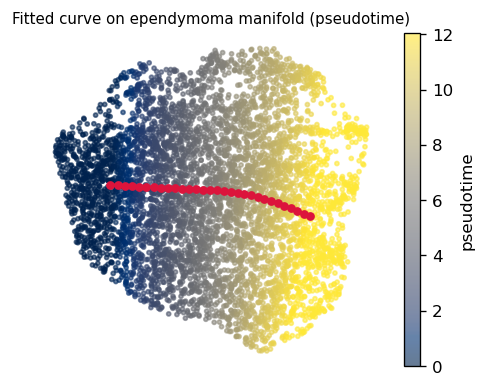

In [9]:
F = np.asarray(sub.uns['graph']['F']); Bc = np.asarray(sub.uns['graph']['B'])
ii, jj = np.where(np.triu(Bc>0))
fig, ax = plt.subplots(figsize=(4.6, 3.6))
sca = ax.scatter(sub.obsm['X_umap'][:,0], sub.obsm['X_umap'][:,1], c=t, cmap='cividis', s=6, alpha=.6)
for a_, b in zip(ii, jj):
    ax.plot([F[0,a_],F[0,b]], [F[1,a_],F[1,b]], '-', color='crimson', lw=2, zorder=5)
ax.scatter(F[0], F[1], c='crimson', s=18, zorder=6)
ax.axis('off'); ax.set_title('Fitted curve on ependymoma manifold (pseudotime)', size=9)
plt.colorbar(sca, ax=ax, label='pseudotime'); plt.show()
print('curve traces a single unbranched arc root->terminus with no self-approach (no fold).')

saved manifold.h5ad + manifold.pdf


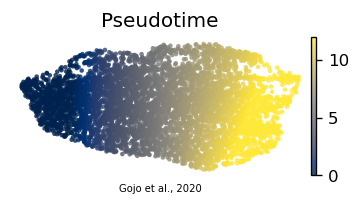

In [10]:
sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg']['NodePositions'])}
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
xl = sub.obsm['X_umap_lin']
xlo, xhi = np.percentile(xl[:,0], [0.3,99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3,99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
plot = sub.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.text(.5, -.12, 'Gojo et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight'); plt.show()
print('saved manifold.h5ad + manifold.pdf')